# Equity Pairs Research: Colab Presentation Notebook

This notebook combines the existing seven-pair research pipeline with the additional Intel/AMD semiconductor pair and the teammate's frozen-hedge and parameter-grid experiments. It is organized into five presentation parts and generates figures at each stage.

**To run in Google Colab:** upload this notebook and `shareable_equity_pairs_research.py` into Colab. Run the cells from top to bottom. Part 1 installs dependencies and asks you to upload the `.py` file; the data are then downloaded from Yahoo Finance. Expect the daily screening and variant grid to take several minutes.

The seven pairs are KO/PEP, XOM/CVX, HD/LOW, V/MA, UPS/FDX, GLD/SLV, and INTC/AMD. The added-pair source mistakenly described INTC/AMD as Intel/Nvidia; this version corrects the rationale to Intel/AMD.




## Part 1 of 5  Data, universe, and price behavior

We fetch auto-adjusted daily OHLC data for all fourteen tickers. First inspect coverage and whether paired adjusted-price histories generally move together. Pair rebasing is for visualization only; the tests use log adjusted prices.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using pipeline script: /content/drive/MyDrive/Stat Arb: Pairs trading/shareable_equity_pairs_research.py

=== Download adjusted daily market data ===
KO: 5,245 daily rows (2006-01-03 to 2026-11-06)
PEP: 5,245 daily rows (2006-01-03 to 2026-11-06)
XOM: 5,245 daily rows (2006-01-03 to 2026-11-06)
CVX: 5,245 daily rows (2006-01-03 to 2026-11-06)
HD: 5,245 daily rows (2006-01-03 to 2026-11-06)
LOW: 5,245 daily rows (2006-01-03 to 2026-11-06)
V: 4,690 daily rows (2008-03-19 to 2026-11-06)
MA: 5,146 daily rows (2006-05-25 to 2026-11-06)
UPS: 5,245 daily rows (2006-01-03 to 2026-11-06)
FDX: 5,245 daily rows (2006-01-03 to 2026-11-06)
GLD: 5,245 daily rows (2006-01-03 to 2026-11-06)
SLV: 5,165 daily rows (2006-04-28 to 2026-11-06)
INTC: 5,245 daily rows (2006-01-03 to 2026-11-06)
AMD: 5,245 daily rows (2006-01-03 to 2026-11-06)
Saved 72,696 rows to /content/drive/MyD

,first_date,last_date,rows
ticker,,,
AMD,2006-01-03,2026-11-06,5245
CVX,2006-01-03,2026-11-06,5245
FDX,2006-01-03,2026-11-06,5245
GLD,2006-01-03,2026-11-06,5245
HD,2006-01-03,2026-11-06,5245
INTC,2006-01-03,2026-11-06,5245
KO,2006-01-03,2026-11-06,5245
LOW,2006-01-03,2026-11-06,5245
MA,2006-05-25,2026-11-06,5146


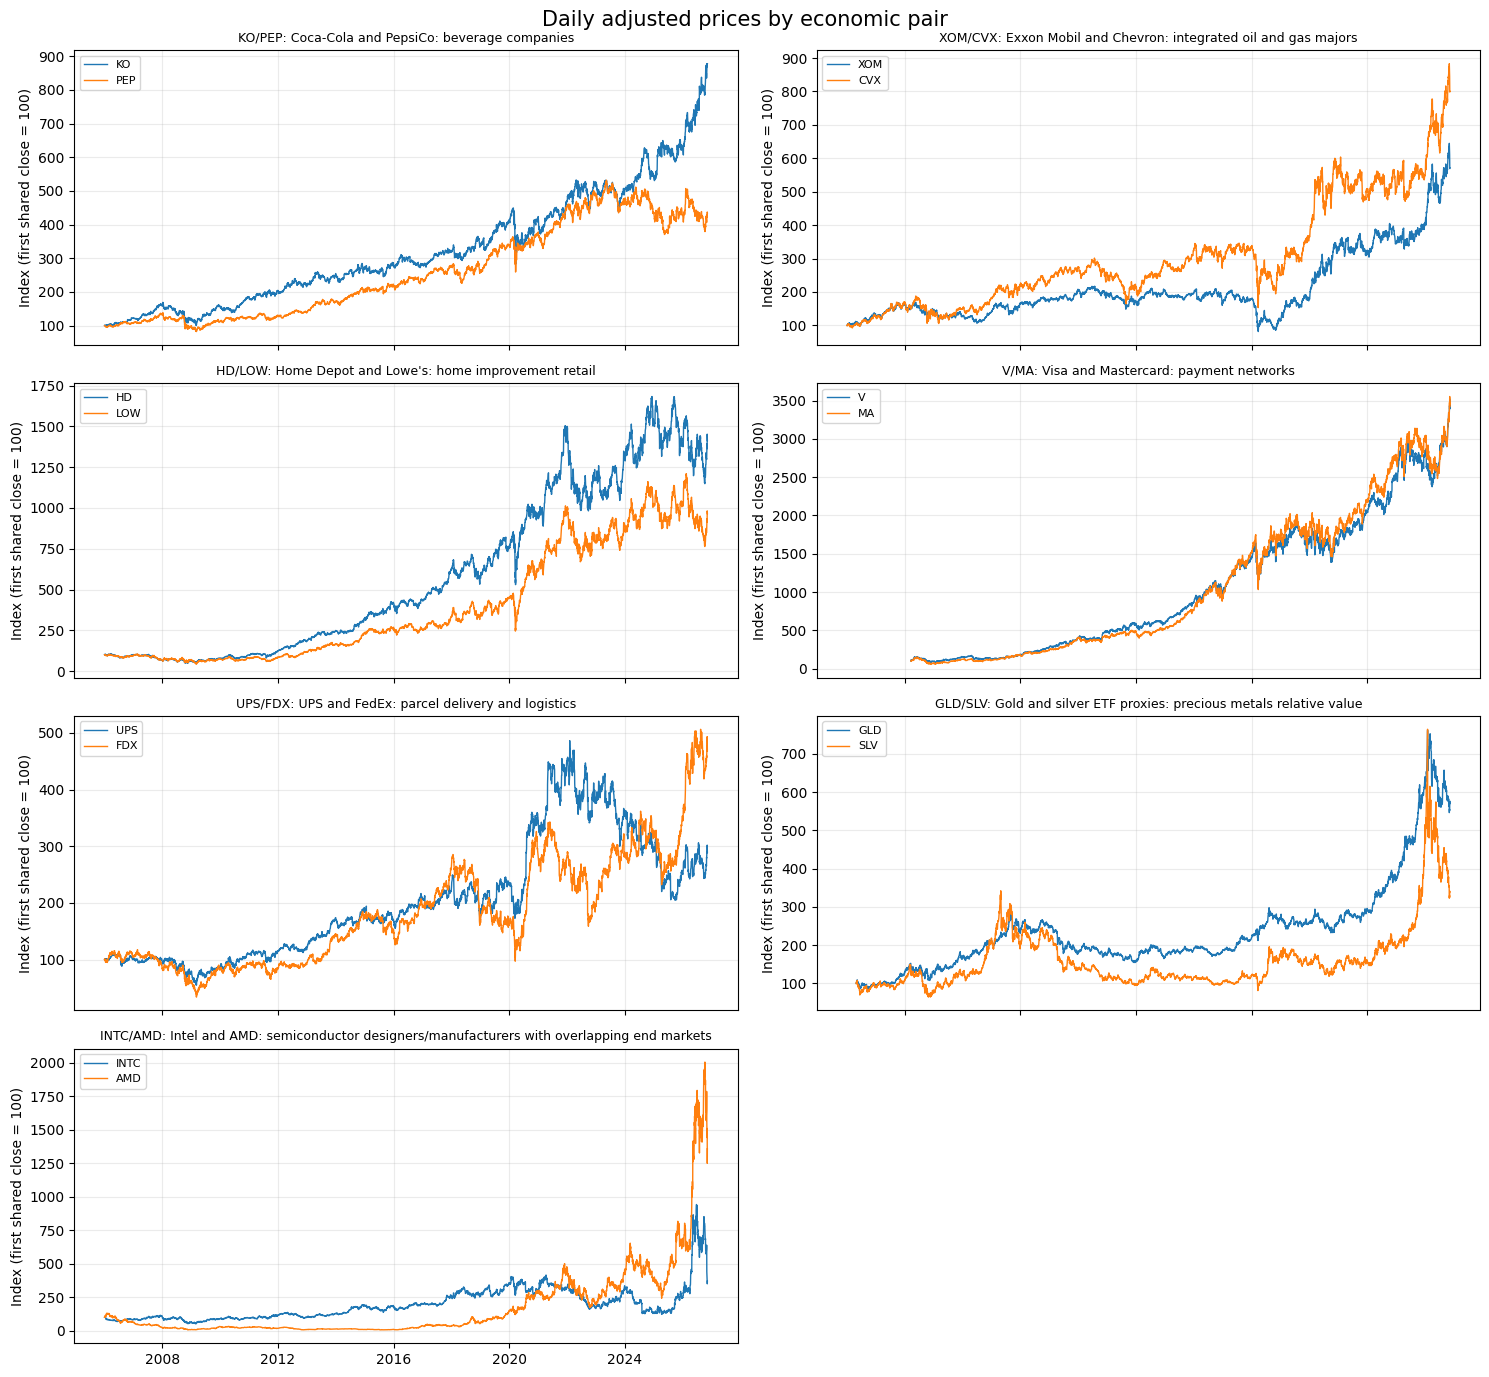

In [11]:
# Colab setup and load the self-contained pipeline script.
!pip -q install yfinance pandas numpy pyarrow statsmodels matplotlib

from google.colab import drive
from pathlib import Path
import importlib.util
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Mount your Google Drive. The script can be anywhere under MyDrive.
drive.mount("/content/drive")
script_name = "shareable_equity_pairs_research.py"
SCRIPT_PATH = None  # Optional: set to e.g. "/content/drive/MyDrive/my-folder/shareable_equity_pairs_research.py"

if SCRIPT_PATH:
    script_path = Path(SCRIPT_PATH)
    if not script_path.is_file():
        raise FileNotFoundError(f"Could not find pipeline script: {script_path}")
else:
    matches = list(Path("/content/drive/MyDrive").rglob(script_name))
    if not matches:
        raise FileNotFoundError(
            f"Could not find {script_name} under MyDrive. Confirm it is uploaded to Drive."
        )
    if len(matches) > 1:
        raise RuntimeError(
            "Found multiple copies of the pipeline script. Set SCRIPT_PATH to the right one:\n"
            + "\n".join(str(path) for path in matches)
        )
    script_path = matches[0]

print(f"Using pipeline script: {script_path}")
spec = importlib.util.spec_from_file_location("equity_pairs_pipeline", script_path)
pipeline = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pipeline)

# Download once; rerunning later parts reuses this saved Parquet file.
pipeline.main(["--stage", "data", "--download", "--start", "2006-01-01"])
prices = pd.read_parquet(pipeline.DOWNLOAD_OUTPUT)
close = prices.pivot(index="date", columns="ticker", values="close").sort_index()
coverage = prices.groupby("ticker").agg(first_date=("date", "min"), last_date=("date", "max"), rows=("date", "count"))
display(coverage)

fig, axes = plt.subplots(4, 2, figsize=(15, 14), sharex=True)
for ax, (left, right, rationale) in zip(axes.flat, pipeline.PAIRS):
    pair = close[[left, right]].dropna()
    rebased = pair / pair.iloc[0] * 100
    ax.plot(rebased.index, rebased[left], label=left, lw=1.0)
    ax.plot(rebased.index, rebased[right], label=right, lw=1.0)
    ax.set_title(f"{left}/{right}: {rationale}", fontsize=9)
    ax.set_ylabel("Index (first shared close = 100)")
    ax.grid(alpha=.25); ax.legend(fontsize=8)
for ax in axes.flat[len(pipeline.PAIRS):]: ax.set_visible(False)
fig.suptitle("Daily adjusted prices by economic pair", fontsize=15)
fig.tight_layout()
display(fig)
plt.close(fig)


## Part 2 of 5  Rolling stationarity, cointegration, and pair selection

Each date uses only the preceding 252 daily closes. Candidate pairs must pass the integration/cointegration and spread-stability checks; Benjamini?Yekutieli adjusts the daily family of seven tests. The output distinguishes ?eligible? tests from selected pairs (the selection also avoids reusing a ticker on that date).


Using existing data: /content/drive/MyDrive/Stat Arb: Pairs trading/data/yfinance_daily.parquet

=== Rolling stationarity/cointegration screen ===
2008-12-24: 500/4994 daily formation screens
2010-12-20: 1000/4994 daily formation screens
2012-12-14: 1500/4994 daily formation screens
2014-12-10: 2000/4994 daily formation screens
2016-12-05: 2500/4994 daily formation screens
2018-11-29: 3000/4994 daily formation screens
2020-11-24: 3500/4994 daily formation screens
2022-11-18: 4000/4994 daily formation screens
2024-11-15: 4500/4994 daily formation screens
   pair  trades  gross_pnl_bps  turnover_units  cost_bps_per_turnover  cost_paid_bps  net_pnl_bps  profitable_trades  win_rate
GLD/SLV       3      47.719523        6.039293                    0.0       0.000000    47.719523                  1  0.333333
GLD/SLV       3      47.719523        6.039293                    1.0       6.039293    41.680230                  1  0.333333
GLD/SLV       3      47.719523        6.039293             

,left,right,eligible_dates,selected_dates
0,GLD,SLV,34,34
6,XOM,CVX,29,29
1,HD,LOW,21,21
5,V,MA,10,10
3,KO,PEP,1,1
2,INTC,AMD,0,0
4,UPS,FDX,0,0


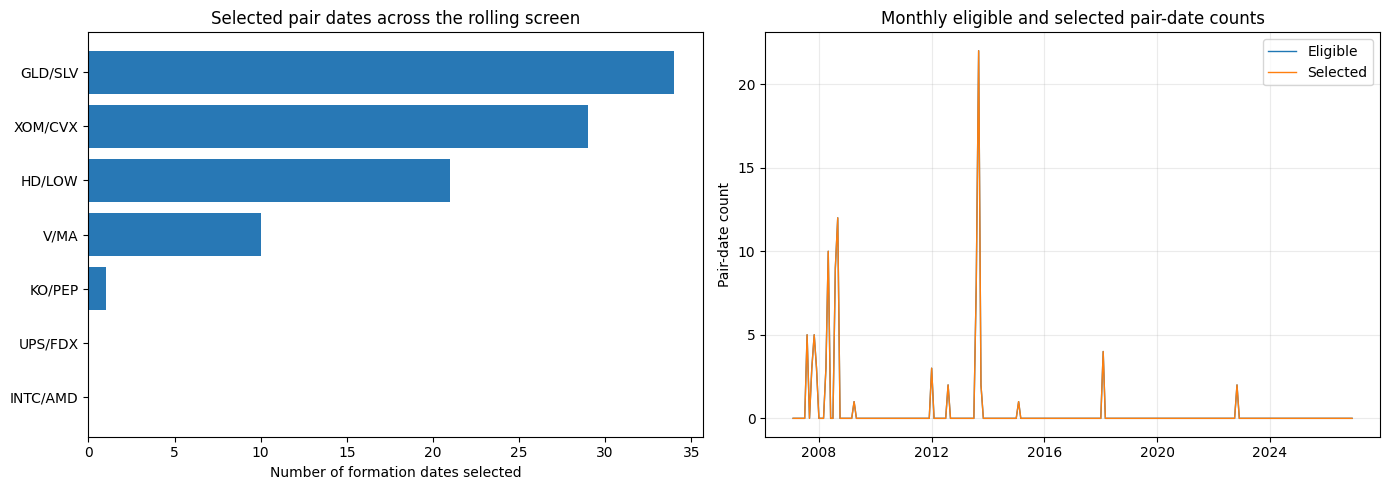

,pair-date observations
screen outcome,
spread_stability_gate_failed,27759
passed gates,6588
insufficient_pair_coverage,611


In [5]:
pipeline.main(["--stage", "screen"])
screens = pd.read_csv(pipeline.ROLLING_OUT_DIR / "rolling_pair_screens.csv", parse_dates=["formation_date"])
selected = screens.loc[screens.selected].copy()
print(f"Formation dates: {screens.formation_date.nunique():,}")
print(f"Selected pair-date instances: {len(selected):,}")
counts = (screens.groupby(["left", "right"], as_index=False)
          .agg(eligible_dates=("eligible", "sum"), selected_dates=("selected", "sum")))
display(counts.sort_values("selected_dates", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
by_pair = counts.assign(pair=counts.left + "/" + counts.right).sort_values("selected_dates")
axes[0].barh(by_pair.pair, by_pair.selected_dates, color="#2878b5")
axes[0].set_title("Selected pair dates across the rolling screen")
axes[0].set_xlabel("Number of formation dates selected")
monthly = (screens.groupby("formation_date").agg(eligible=("eligible", "sum"), selected=("selected", "sum"))
           .resample("ME").sum())
axes[1].plot(monthly.index, monthly.eligible, label="Eligible", lw=1.0)
axes[1].plot(monthly.index, monthly.selected, label="Selected", lw=1.0)
axes[1].set_title("Monthly eligible and selected pair-date counts")
axes[1].set_ylabel("Pair-date count"); axes[1].legend(); axes[1].grid(alpha=.25)
fig.tight_layout(); display(fig); plt.close(fig)

reason_counts = screens.failure_reason.fillna("").replace("", "passed gates").value_counts().head(10)
display(reason_counts.rename_axis("screen outcome").to_frame("pair-date observations"))


## Part 3 of 5 Trading rules, walk-forward thresholds, and Kalman comparison

The main strategy uses a fixed economic watchlist after 252 sessions of price coverage. It compares rolling OLS with a causal Kalman hedge; z-score thresholds are selected annually using only the trailing three-year training period, with next-session-open execution. The default portfolio account has seven fixed capital units, one target gross-notional unit per pair, and no compounding.


Using existing data: /content/drive/MyDrive/Stat Arb: Pairs trading/data/yfinance_daily.parquet

=== OLS/Kalman and walk-forward backtests ===
Testing fixed entry z=0.5
Testing fixed entry z=1
Testing fixed entry z=1.5
Testing fixed entry z=2.5
Testing Kalman fixed entry z=0.5
Testing Kalman fixed entry z=1
Testing Kalman fixed entry z=1.5
Testing Kalman fixed entry z=2.5
                               design pair  trades  gross_pnl_bps  turnover_units  cost_bps_per_turnover  cost_paid_bps   net_pnl_bps  profitable_trades  win_rate
fixed_watchlist_252bar_warmup_rehedge  ALL    1253    7905.895123     2833.591649                    0.0       0.000000   7905.895123                707  0.564246
fixed_watchlist_252bar_warmup_rehedge  ALL    1253    7905.895123     2833.591649                    1.0    2833.591649   5072.303474                699  0.557861
fixed_watchlist_252bar_warmup_rehedge  ALL    1253    7905.895123     2833.591649                    5.0   14167.958244  -6262.063122   

,design,trades,gross_pnl_bps,cost_bps_per_turnover,net_pnl_bps
1,fixed_watchlist_252bar_warmup_rehedge,1253,7905.895123,1.0,5072.303474
2,fixed_watchlist_252bar_warmup_rehedge,1253,7905.895123,5.0,-6262.063122
5,zstar_walkforward,1020,-3694.558847,1.0,-6008.306246
6,zstar_walkforward,1020,-3694.558847,5.0,-15263.295844
9,kalman_fixed_z2,569,9934.438716,1.0,8683.258694
10,kalman_fixed_z2,569,9934.438716,5.0,3678.538603
13,kalman_zstar_walkforward,842,-1933.113587,1.0,-3752.727935
14,kalman_zstar_walkforward,842,-1933.113587,5.0,-11031.185324
17,baseline_dynamic_z_immediate_exit,6,31.328691,1.0,19.122386
18,baseline_dynamic_z_immediate_exit,6,31.328691,5.0,-29.702833


,model,cost_bps_per_turnover,completed_round_trips,cumulative_return_pct,max_drawdown_pct,annualized_sharpe
0,Rolling OLS,1.0,1020,-8.583295,-16.267477,-0.131016
1,Rolling OLS,5.0,1020,-21.804708,-24.581667,-0.332817
2,Kalman,1.0,842,-5.361040,-11.079276,-0.084886
3,Kalman,5.0,842,-15.758836,-19.756698,-0.249426


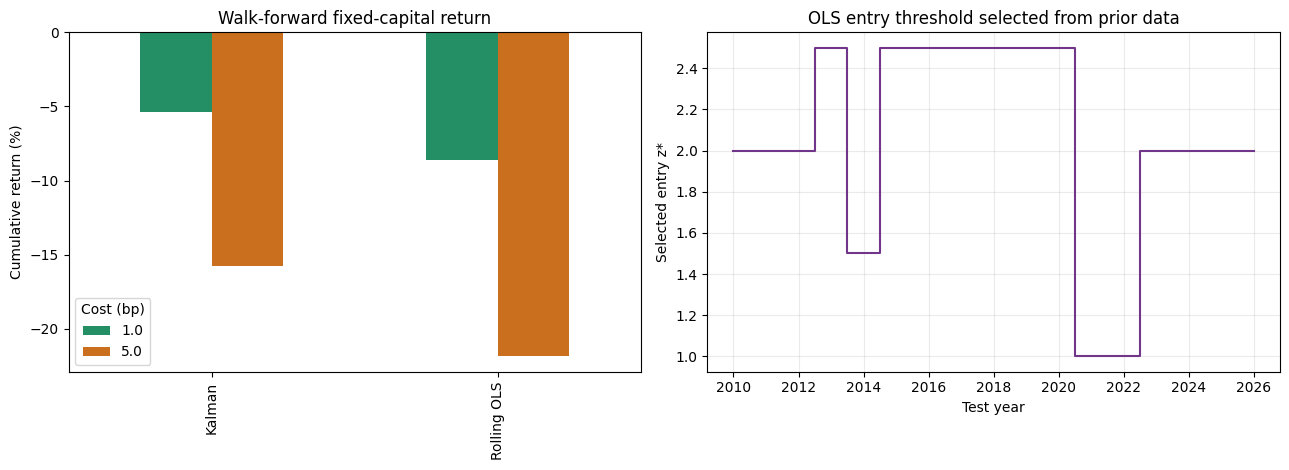

In [6]:
pipeline.main(["--stage", "backtest", "--hedge-mode", "rehedge"])
design = pipeline.DESIGN_OUT_DIR
comparison = pd.read_csv(design / "design_comparison.csv")
headline = comparison.loc[comparison.pair.eq("ALL") & comparison.cost_bps_per_turnover.isin([1.0, 5.0])]
display(headline[["design", "trades", "gross_pnl_bps", "cost_bps_per_turnover", "net_pnl_bps"]])
portfolio = pd.read_csv(design / "portfolio_summary.csv")
display(portfolio[["model", "cost_bps_per_turnover", "completed_round_trips", "cumulative_return_pct", "max_drawdown_pct", "annualized_sharpe"]])

walk = pd.read_csv(design / "zstar_threshold_schedule.csv", parse_dates=["train_end_exclusive"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_data = portfolio.pivot(index="model", columns="cost_bps_per_turnover", values="cumulative_return_pct")
plot_data.plot(kind="bar", ax=axes[0], color={1.0:"#248f65",5.0:"#ca6f1e"})
axes[0].axhline(0, color="black", lw=.7); axes[0].set_title("Walk-forward fixed-capital return")
axes[0].set_ylabel("Cumulative return (%)"); axes[0].set_xlabel(""); axes[0].legend(title="Cost (bp)")
axes[1].step(walk.test_year, walk.selected_entry_z, where="mid", color="#71368a")
axes[1].set_title("OLS entry threshold selected from prior data")
axes[1].set_xlabel("Test year"); axes[1].set_ylabel("Selected entry z*"); axes[1].grid(alpha=.25)
fig.tight_layout(); display(fig); plt.close(fig)


## Part 4 of 5 frozen hedge and parameter grid

A frozen-hedge run holds entry alpha, beta, and spread scale fixed for the trade. The diagnostic grid compares frozen and daily-rehedged OLS across 60/120/252-session estimation windows and the configured entry-z thresholds. These are descriptive comparisons, not a license to choose the best full-sample result; selecting parameters on the same history would overfit.


Using existing data: /content/drive/MyDrive/Stat Arb: Pairs trading/data/yfinance_daily.parquet

=== OLS/Kalman and walk-forward backtests ===
Grid: rehedge, lookback=60, entry z=0.5
Grid: rehedge, lookback=60, entry z=1
Grid: rehedge, lookback=60, entry z=1.5
Grid: rehedge, lookback=60, entry z=2
Grid: rehedge, lookback=60, entry z=2.5
Grid: frozen, lookback=60, entry z=0.5
Grid: frozen, lookback=60, entry z=1
Grid: frozen, lookback=60, entry z=1.5
Grid: frozen, lookback=60, entry z=2
Grid: frozen, lookback=60, entry z=2.5
Grid: rehedge, lookback=120, entry z=0.5
Grid: rehedge, lookback=120, entry z=1
Grid: rehedge, lookback=120, entry z=1.5
Grid: rehedge, lookback=120, entry z=2
Grid: rehedge, lookback=120, entry z=2.5
Grid: frozen, lookback=120, entry z=0.5
Grid: frozen, lookback=120, entry z=1
Grid: frozen, lookback=120, entry z=1.5
Grid: frozen, lookback=120, entry z=2
Grid: frozen, lookback=120, entry z=2.5
Grid: rehedge, lookback=252, entry z=0.5
Grid: rehedge, lookback=252, ent

,hedge_mode,lookback,entry_z,trades,gross_bps_per_trade,gross_total_bps,win_rate,mean_holding_sessions,gross_mean_t_stat
5,frozen,60,0.5,1522,-7.687724,-11700.716356,0.666229,15.530880,-0.894788
6,frozen,60,1.0,1247,3.948468,4923.739411,0.590217,18.691259,0.362520
7,frozen,60,1.5,1049,4.129125,4331.452433,0.511916,20.694948,0.339469
8,frozen,60,2.0,879,3.140212,2760.246786,0.425484,19.747440,0.240437
9,frozen,60,2.5,734,-3.012790,-2211.387654,0.369210,15.140327,-0.246231
15,frozen,120,0.5,927,-4.734391,-4388.780483,0.706580,25.822006,-0.317149
16,frozen,120,1.0,705,-13.906407,-9804.017163,0.614184,33.394326,-0.746769
17,frozen,120,1.5,610,-12.241976,-7467.605276,0.536066,36.595082,-0.569483
18,frozen,120,2.0,503,-18.224102,-9166.723381,0.423459,35.737575,-0.768840
19,frozen,120,2.5,421,-18.020719,-7586.722878,0.349169,27.199525,-0.899814


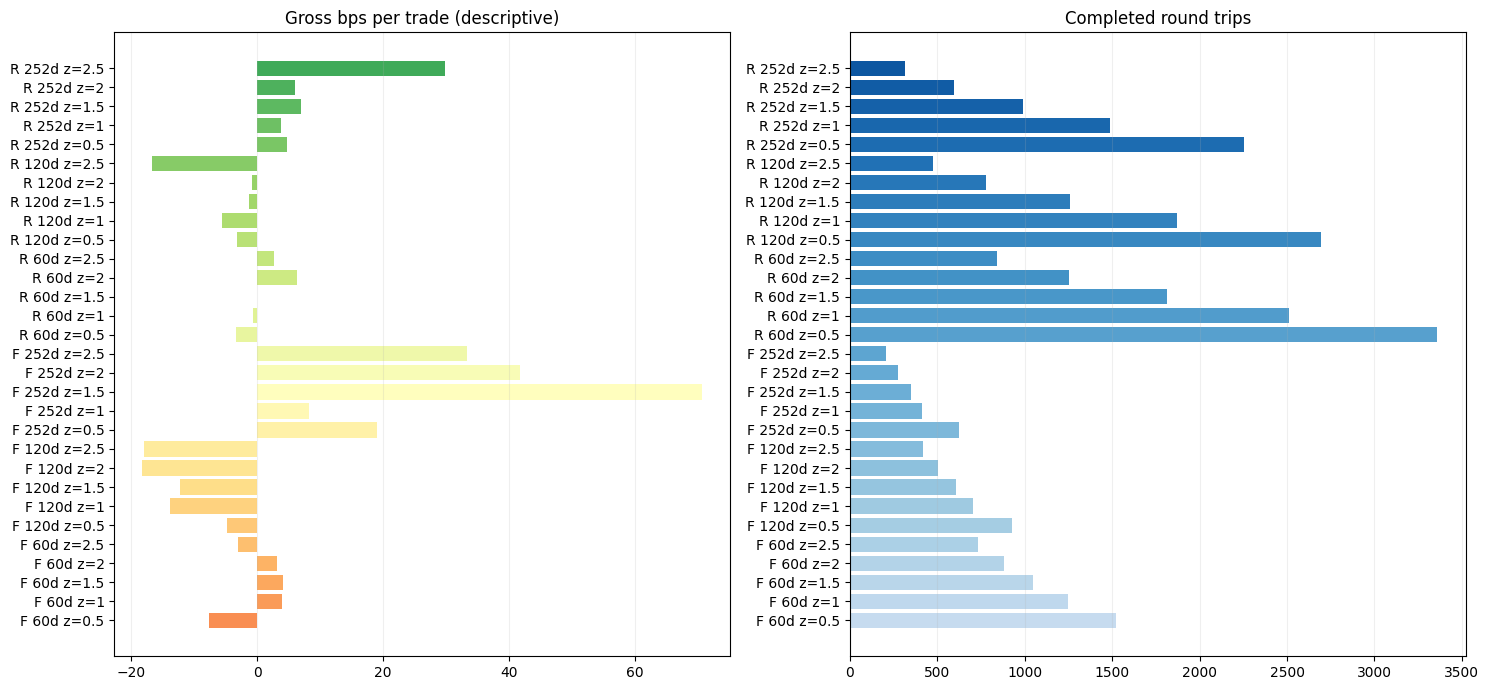

In [7]:
variant_dir = pipeline.ROOT / "outputs" / "frozen_and_grid"
pipeline.main(["--stage", "backtest", "--hedge-mode", "frozen", "--skip-zstar",
               "--grid", "--grid-lookbacks", "60,120,252", "--output", str(variant_dir)])
grid = pd.read_csv(variant_dir / "variant_grid.csv")
display(grid.sort_values(["hedge_mode", "lookback", "entry_z"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title, cmap in [
    (axes[0], "gross_bps_per_trade", "Gross bps per trade (descriptive)", "RdYlGn"),
    (axes[1], "trades", "Completed round trips", "Blues"),
]:
    modes = sorted(grid.hedge_mode.unique())
    labels=[]; values=[]
    for mode in modes:
        sub=grid.loc[grid.hedge_mode.eq(mode)].sort_values(["lookback","entry_z"])
        labels.extend([f"{mode[:1].upper()} {int(r.lookback)}d z={r.entry_z:g}" for r in sub.itertuples()])
        values.extend(sub[metric].fillna(0).tolist())
    ax.barh(labels, values, color=plt.get_cmap(cmap)(np.linspace(.25,.85,len(values))))
    ax.set_title(title); ax.grid(axis="x", alpha=.2)
fig.set_size_inches(15, max(7, len(grid)*.22)); fig.tight_layout(); display(fig); plt.close(fig)


## Part 5 of 5 ? Full visual report and key figures

Regenerate the pair-by-pair histories, rolling spread and hedge-ratio charts, NAV/risk figures, and OLS-versus-Kalman comparison. The INTC/AMD pair also receives its own three-panel chart. The 1 bp case is the standard modeled cost; 5 bp is a sensitivity.


In [12]:
pipeline.main(["--stage", "visuals"])
visuals = pipeline.VISUAL_OUT_DIR
for filename in [
    "01_adjusted_close_time_series.png",
    "02_pair_rebased_price_histories.png",
    "03_rolling_spread_zscores_and_trades.png",
    "04_rolling_hedge_ratios.png",
    "06_cumulative_pnl_and_rolling_risk.png",
    "07_zstar_chronological_cv_sensitivity.png",
    "09_kalman_vs_rolling_ols.png",
    "10_portfolio_account_nav_risk_and_exposure.png",
]:
    print(filename)
    display(Image(filename=str(visuals / filename)))

intc_amd = visuals / "by_pair" / "INTC_AMD_diagnostics.png"
if intc_amd.exists():
    print("Added pair: INTC/AMD")
    display(Image(filename=str(intc_amd)))
else:
    print("Pair-specific visuals are in:", visuals / "by_pair")


Output hidden; open in https://colab.research.google.com to view.

## Presentation takeaway

The workflow now contains seven economically motivated pairs, including the teammate's INTC/AMD addition. It compares a rolling statistical screen with a fixed-watchlist trading diagnostic, rolling OLS and Kalman hedge estimation, frozen versus rehedged positions, and a lookback/entry-threshold grid. Report both trade counts and net-of-modeled-cost portfolio metrics, and state clearly that all outputs are historical research estimates rather than live execution results.
